## Project Motivation
Standard GNN classifiers achieve high global accuracy, but minority-class recall can collapse on rare subpopulations (e.g., CD34+ cells at <1%). Continuous cellular differentiation places rare cells at heterophilous cluster boundaries where isotropic message passing averages minority features directly into majority centroids. We evaluate whether an adaptive, homophily-gated architecture preserves minority decision boundaries under extreme scarcity.


## Project Description
We formulate single-cell annotation as transductive semi-supervised node classification on Zheng 68k PBMC (N68,000, 11 discrete classes) across label-scarcity splits (1%, 2%, 5%, 10%, 20%, or 5–20 labeled cells/class). Severe class imbalance (abundant T cells to <1% CD34+ cells) makes this a natural test of minority-class smoothing under graph message passing. 

In [51]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
from IPython.display import display

sc.settings.verbosity = 2
sc.set_figure_params(dpi=90, facecolor="white")
sns.set_theme(style="whitegrid")
SEED = 42
DATA_PATH = Path("data/PBMC/pbmc68k.h5ad")
if not DATA_PATH.is_file(): 
    print("downloading file ")
    
    import scvelo as scv
    adata_source = scv.datasets.pbmc68k(file_path=str(DATA_PATH))
    del adata_source # standardise read format 
print("Input:", DATA_PATH.resolve(), f"({DATA_PATH.stat().st_size / 2**20:,.1f} MiB)")
adata = sc.read_h5ad(DATA_PATH)
print(adata)


downloading file 
try downloading from url
https://ndownloader.figshare.com/files/27686886
... this may take a while but only happens once


  0%|          | 0.00/118M [00:00<?, ?B/s]

Input: /Users/maximyam/Documents/test/MComp/Y1S1/CS5284/Graph-ML-/data/PBMC/pbmc68k.h5ad (118.0 MiB)
AnnData object with n_obs × n_vars = 65877 × 33939
    obs: 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    obsm: 'X_tsne'
    layers: 'spliced', 'unspliced'


| Item | Meaning | Role in your graph-versus-classifier study |
| --- | --- | --- |
| `adata.obs.index` | Cell barcodes, such as `AAACATACACCCAA` | Stable row identifiers. Use them to align predictions with cells. Keep them exactly as stored; adding or stripping `-1` without checking can cause mismatches. |
| `adata.obs["celltype"]` | A categorical annotation with **11 classes** and no missing values | The likely prediction target. Examine counts per class and split cells into train/test sets before evaluating either model. Do **not** feed this column into the classifier, PCA, or graph construction. |

In [52]:
print(f"Number of barcodes {adata.obs.index.nunique()} \t ==> \t\t [Example]: { adata.obs.index[0]}") # 65877 barcodes 
print(f"Number of type {adata.obs.celltype.nunique()} \t\t ==> \t\t [Example]: { adata.obs.celltype[0]}") # 65877 barcodes 
display(adata.obs)


Number of barcodes 65877 	 ==> 		 [Example]: AAACATACACCCAA
Number of type 11 		 ==> 		 [Example]: CD8+ Cytotoxic T


,celltype
AAACATACACCCAA,CD8+ Cytotoxic T
AAACATACCCCTCA,CD8+/CD45RA+ Naive Cytotoxic
AAACATACCGGAGA,CD4+/CD45RO+ Memory
AAACATACTAACCG,CD19+ B
AAACATACTCTTCA,CD4+/CD25 T Reg
...,...
TTTGCATGAGCCTA,CD8+ Cytotoxic T
TTTGCATGCTAGCA,CD8+/CD45RA+ Naive Cytotoxic
TTTGCATGCTGCAA,CD8+ Cytotoxic T
TTTGCATGGCTCCT,CD8+ Cytotoxic T


| Item | Meaning | Why it matters |
| --- | --- | --- |
| `adata.var` | Gene names, such as `FAM138A` | These identify the 33,939 expression features. Keep the same selected genes, in the same order, for both models. |
| `Accession` | A distinct Ensembl-style gene identifier for each gene | Useful for unambiguous gene tracking, especially where names are similar. It is an identifier, not an expression value. |
| `Chromosome` | The chromosome or sequence listed for each gene | Useful for checking gene composition, including whether mitochondrial genes can be identified. Its 40 categories need inspection before interpretation. |
| `Start`, `End` | Genomic coordinates recorded for each gene | Describe gene locations. They do not give the cell’s expression level and should not automatically become model features. The genome assembly is not specified by this output. |
| `Strand` | `+` or `-` genomic strand | Describes gene orientation. It is relevant to gene annotation, but not a cell-type feature by itself. |

In [53]:
print(f"Gene Name {adata.var.index.nunique()} \t\t ==> \t [Example]: { adata.var.index[1]}") # 33939 Gene 
print(f"Ensembl identifier {adata.var.Accession.nunique()} \t\t ==> \t [Example]: { adata.var.Accession[0]}") # 33939 
print(f"Chromosone {adata.var.Chromosome.nunique()} \t\t ==> \t [Example]: { adata.var.Chromosome[0]}") # 40 chromosone types
print(f"Start,End Geometric Coordinate of gene \t\t ==> \t [Example]: { adata.var.Start[0], adata.var.End[0]  }") # Coordinates of gene 
print()
print(f"Strand {adata.var.Strand.nunique()} \t\t ==> \t \n[Example]: { adata.var.Strand.value_counts()}") # 40 chromosone types 


Gene Name 33939 		 ==> 	 [Example]: AL627309.1
Ensembl identifier 33939 		 ==> 	 [Example]: ENSG00000237613
Chromosone 40 		 ==> 	 [Example]: 1
Start,End Geometric Coordinate of gene 		 ==> 	 [Example]: (34554, 36081)

Strand 2 		 ==> 	 
[Example]: Strand
+    17134
-    16805
Name: count, dtype: int64


In [54]:
display(adata.var)

,Accession,Chromosome,End,Start,Strand
Gene,,,,,
FAM138A,ENSG00000237613,1,36081,34554,-
AL627309.1,ENSG00000238009,1,133723,89295,-
AL627309.3,ENSG00000239945,1,91105,89551,-
AL627309.2,ENSG00000239906,1,140339,139790,-
OR4F29,ENSG00000284733,1,451697,450703,-
...,...,...,...,...,...
TTTY4B,ENSG00000235412,Y,24607025,24570202,+
BPY2B,ENSG00000183795,Y,24639207,24607560,+
DAZ4,ENSG00000205916,Y,24907040,24833843,+


| Item | What your output shows | Interpretation for this project |
| --- | --- | --- |
| `adaat.X` | A 65,877 × 33,939 `float32` matrix | The main expression matrix and potential common feature source. **`float32` does not establish whether these are raw counts, normalized counts, or log values.** Check before running the notebook’s count-based QC and normalization. |
| `adaat.layers["spliced"]` | A same-size `uint16` matrix | Counts assigned as spliced transcripts. Spliced, mature RNA abundance for one cell and one gene. Potentially useful for RNA-velocity analyses; its values and relationship to `X` need checking before using it as an expression feature source. |
| `adaat.layers["unspliced"]` | A same-size `uint16` matrix | Counts assigned as unspliced transcripts. Unspliced, precursor RNA abundance for one cell and one gene. The same caution applies. Do not assume `spliced + unspliced == X`. |
| `obsm["X_tsne"]` | Two coordinates per cell | An existing **visualization**, useful for looking at how annotated cells are arranged. It is not evidence that a neighbor graph is stored and should not be used as the shared expression features for the comparison. |

In [55]:
# adata.X, adata.obsm, adata.layers
adata.obsm['X_tsne'].shape


print(f"Feature Matrx {adata.X.shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.X[:3, :3].toarray()}")
print('\n\n')


print(f"Spliced Matrx {adata.layers['spliced'].shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.layers['spliced'][:3, :3].toarray()}")
print('\n\n')


print(f"Unspliced Matrx {adata.layers['unspliced'].shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.layers['unspliced'][:3, :3].toarray()}")
print('\n\n')

print(f"obsm tsne size {adata.obsm['X_tsne'].shape} \t\t ==> \t \n[Example first 2 row]:\n{ adata.obsm['X_tsne'][:2, :]}") # tSNE coord of cell 



Feature Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]



Spliced Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]



Unspliced Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]



obsm tsne size (65877, 2) 		 ==> 	 
[Example first 2 row]:
[[  7.56553972   0.44137032]
 [  2.55262557 -25.78667227]]


In [56]:
print("Shape (cells, genes):", adata.shape)
print("X:", type(adata.X).__name__, adata.X.dtype)
print("obs columns:", list(adata.obs.columns))
print("var columns:", list(adata.var.columns))
print("layers:", {k: (v.shape, str(v.dtype)) for k, v in adata.layers.items()})
print("obsm:", {k: v.shape for k, v in adata.obsm.items()})
print("Unique cell IDs:", adata.obs_names.is_unique, "duplicate count:", adata.obs_names.duplicated().sum())
print("Unique gene IDs:", adata.var_names.is_unique, "duplicate count:", adata.var_names.duplicated().sum())
display(adata.obs.head(), adata.var.head())
display(pd.DataFrame({"cell_id": adata.obs_names[:10]}))
if not adata.obs_names.is_unique:
    raise ValueError("Repeated cell IDs in the file: inspect adata.obs_names before proceeding; do not strip barcode suffixes.")
if not adata.var_names.is_unique:
    warnings.warn("Duplicate gene names: preserving the originals in var['original_gene_id'] and making analysis names unique.")
    adata.var["original_gene_id"] = adata.var_names.astype(str)
    adata.var_names_make_unique()


Shape (cells, genes): (65877, 33939)
X: csr_matrix float32
obs columns: ['celltype']
var columns: ['Accession', 'Chromosome', 'End', 'Start', 'Strand']
layers: {'spliced': ((65877, 33939), 'uint16'), 'unspliced': ((65877, 33939), 'uint16')}
obsm: {'X_tsne': (65877, 2)}
Unique cell IDs: True duplicate count: 0
Unique gene IDs: True duplicate count: 0


,celltype
AAACATACACCCAA,CD8+ Cytotoxic T
AAACATACCCCTCA,CD8+/CD45RA+ Naive Cytotoxic
AAACATACCGGAGA,CD4+/CD45RO+ Memory
AAACATACTAACCG,CD19+ B
AAACATACTCTTCA,CD4+/CD25 T Reg


,Accession,Chromosome,End,Start,Strand
Gene,,,,,
FAM138A,ENSG00000237613,1,36081,34554,-
AL627309.1,ENSG00000238009,1,133723,89295,-
AL627309.3,ENSG00000239945,1,91105,89551,-
AL627309.2,ENSG00000239906,1,140339,139790,-
OR4F29,ENSG00000284733,1,451697,450703,-


,cell_id
0,AAACATACACCCAA
1,AAACATACCCCTCA
2,AAACATACCGGAGA
3,AAACATACTAACCG
4,AAACATACTCTTCA
5,AAACATACTGGATC
6,AAACATACTGTCTT
7,AAACATACTTCTAC
8,AAACATTGCTGCTC
9,AAACATTGCTTCGC


In [57]:
def matrix_snapshot(matrix, max_values=100_000, seed=SEED):
    """Small diagnostic sample; does not densify a cell-by-gene matrix."""
    rng = np.random.default_rng(seed)
    values = matrix.data if sp.issparse(matrix) else np.asarray(matrix).ravel()
    values = np.asarray(values)
    if values.size > max_values:
        values = values[rng.integers(0, values.size, size=max_values)]
    if values.size == 0:
        return dict(dtype=str(matrix.dtype), sampled=0, min=np.nan, max=np.nan,
                    nonnegative=True, integer_like=True, finite=True)
    return dict(dtype=str(matrix.dtype), sampled=len(values), min=float(values.min()),
                max=float(values.max()), nonnegative=bool(np.all(values >= 0)),
                integer_like=bool(np.allclose(values, np.rint(values), atol=1e-6, rtol=0)),
                finite=bool(np.isfinite(values).all()))

matrix_report = pd.DataFrame({name: matrix_snapshot(matrix) for name, matrix in
                              {"X": adata.X, **dict(adata.layers)}.items()}).T
display(matrix_report)


,dtype,sampled,min,max,nonnegative,integer_like,finite
X,float32,100000,1.0,16.0,True,True,True
spliced,uint16,100000,1.0,16.0,True,True,True
unspliced,uint16,100000,1.0,12.0,True,True,True


In [58]:
COUNT_SOURCE = "counts" if "counts" in adata.layers else "X"  # Edit if your actual count layer has another name.
assert COUNT_SOURCE == "X" or COUNT_SOURCE in adata.layers
counts = adata.X if COUNT_SOURCE == "X" else adata.layers[COUNT_SOURCE]

def validate_counts(matrix):
    values = matrix.data if sp.issparse(matrix) else np.asarray(matrix)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Selected matrix contains nonfinite or negative values.")
    if not np.allclose(values, np.rint(values), atol=1e-6, rtol=0):
        raise ValueError("Selected matrix is not integer-like. Set COUNT_SOURCE to a genuine raw-count layer; do not normalize this matrix again.")
    if sp.issparse(matrix) and matrix.nnz and np.any(matrix.data == 0):
        warnings.warn("Sparse matrix contains explicitly stored zeros; QC remains valid.")

validate_counts(counts)
print("Validated count source:", COUNT_SOURCE, counts.shape)


Validated count source: X (65877, 33939)


#### Review metadata distributions without assuming any column is a verified label. Mitochondrial gene detection relies on gene names stored in this file and may be unavailable for Ensembl-style IDs. Such missing metrics are explicitly skipped.

In [59]:
metadata_summary = pd.DataFrame({
    "dtype": adata.obs.dtypes.astype(str),
    "missing_n": adata.obs.isna().sum(),
    "unique_n": adata.obs.nunique(dropna=True),
}).sort_index()
display(metadata_summary)
for column in adata.obs.columns:
    if adata.obs[column].nunique(dropna=True) <= 30:
        print(f"\n{column}:")
        display(adata.obs[column].astype("string").value_counts(dropna=False).head(30).to_frame("cells"))


,dtype,missing_n,unique_n
celltype,category,0,11



celltype:


,cells
celltype,
CD8+ Cytotoxic T,19941
CD8+/CD45RA+ Naive Cytotoxic,16032
CD56+ NK,8440
CD4+/CD25 T Reg,5921
CD19+ B,5674
CD4+/CD45RO+ Memory,2945
CD14+ Monocyte,2749
Dendritic,2014
CD4+/CD45RA+/CD25- Naive T,1802


In [60]:
qc = adata.copy()
if COUNT_SOURCE != "X":
    qc.X = counts.copy()
    
# Preserve original expression in `adata`; all downstream changes are made to `qc` or `work`.
gene_symbols = qc.var["gene_symbols"].astype(str) if "gene_symbols" in qc.var else pd.Series(qc.var_names.astype(str), index=qc.var_names)
qc.var["mt"] = gene_symbols.str.upper().str.startswith("MT-").to_numpy()
print("Mitochondrial genes recognized:", int(qc.var["mt"].sum()))
if not qc.var["mt"].any():
    warnings.warn("No MT- gene names found. Mitochondrial percentage cannot be interpreted from these identifiers.")
qc_vars = ["mt"] if qc.var["mt"].any() else []
sc.pp.calculate_qc_metrics(qc, qc_vars=qc_vars, percent_top=None, log1p=False, inplace=True)
qc_cols = ["total_counts", "n_genes_by_counts"] + (["pct_counts_mt"] if qc_vars else [])
display(qc.obs[qc_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)
display(qc.var[["n_cells_by_counts", "total_counts"]].describe(percentiles=[.01, .5, .99]).T)
print("Zero-count cells:", int((qc.obs.total_counts == 0).sum()))
print("Never-observed genes:", int((qc.var.n_cells_by_counts == 0).sum()))


Mitochondrial genes recognized: 13


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
total_counts,65877.0,148.584961,33.414818,0.0,40.0,79.0,135.000000,155.000000,171.000000,190.000000,204.000000,244.000000
n_genes_by_counts,65877.0,107.948738,21.532068,0.0,36.0,65.0,98.000000,111.000000,122.000000,136.000000,146.000000,171.000000
pct_counts_mt,65876.0,2.177375,1.593788,0.0,0.0,0.0,1.129943,1.941748,2.994012,4.929577,6.802722,38.392857


,count,mean,std,min,1%,50%,99%,max
n_cells_by_counts,33939.0,209.532956,1932.852793,0.0,0.0,0.0,2861.78,60907.0
total_counts,33939.0,288.409515,3787.079834,0.0,0.0,0.0,3133.10,204668.0


Zero-count cells: 1
Never-observed genes: 17817


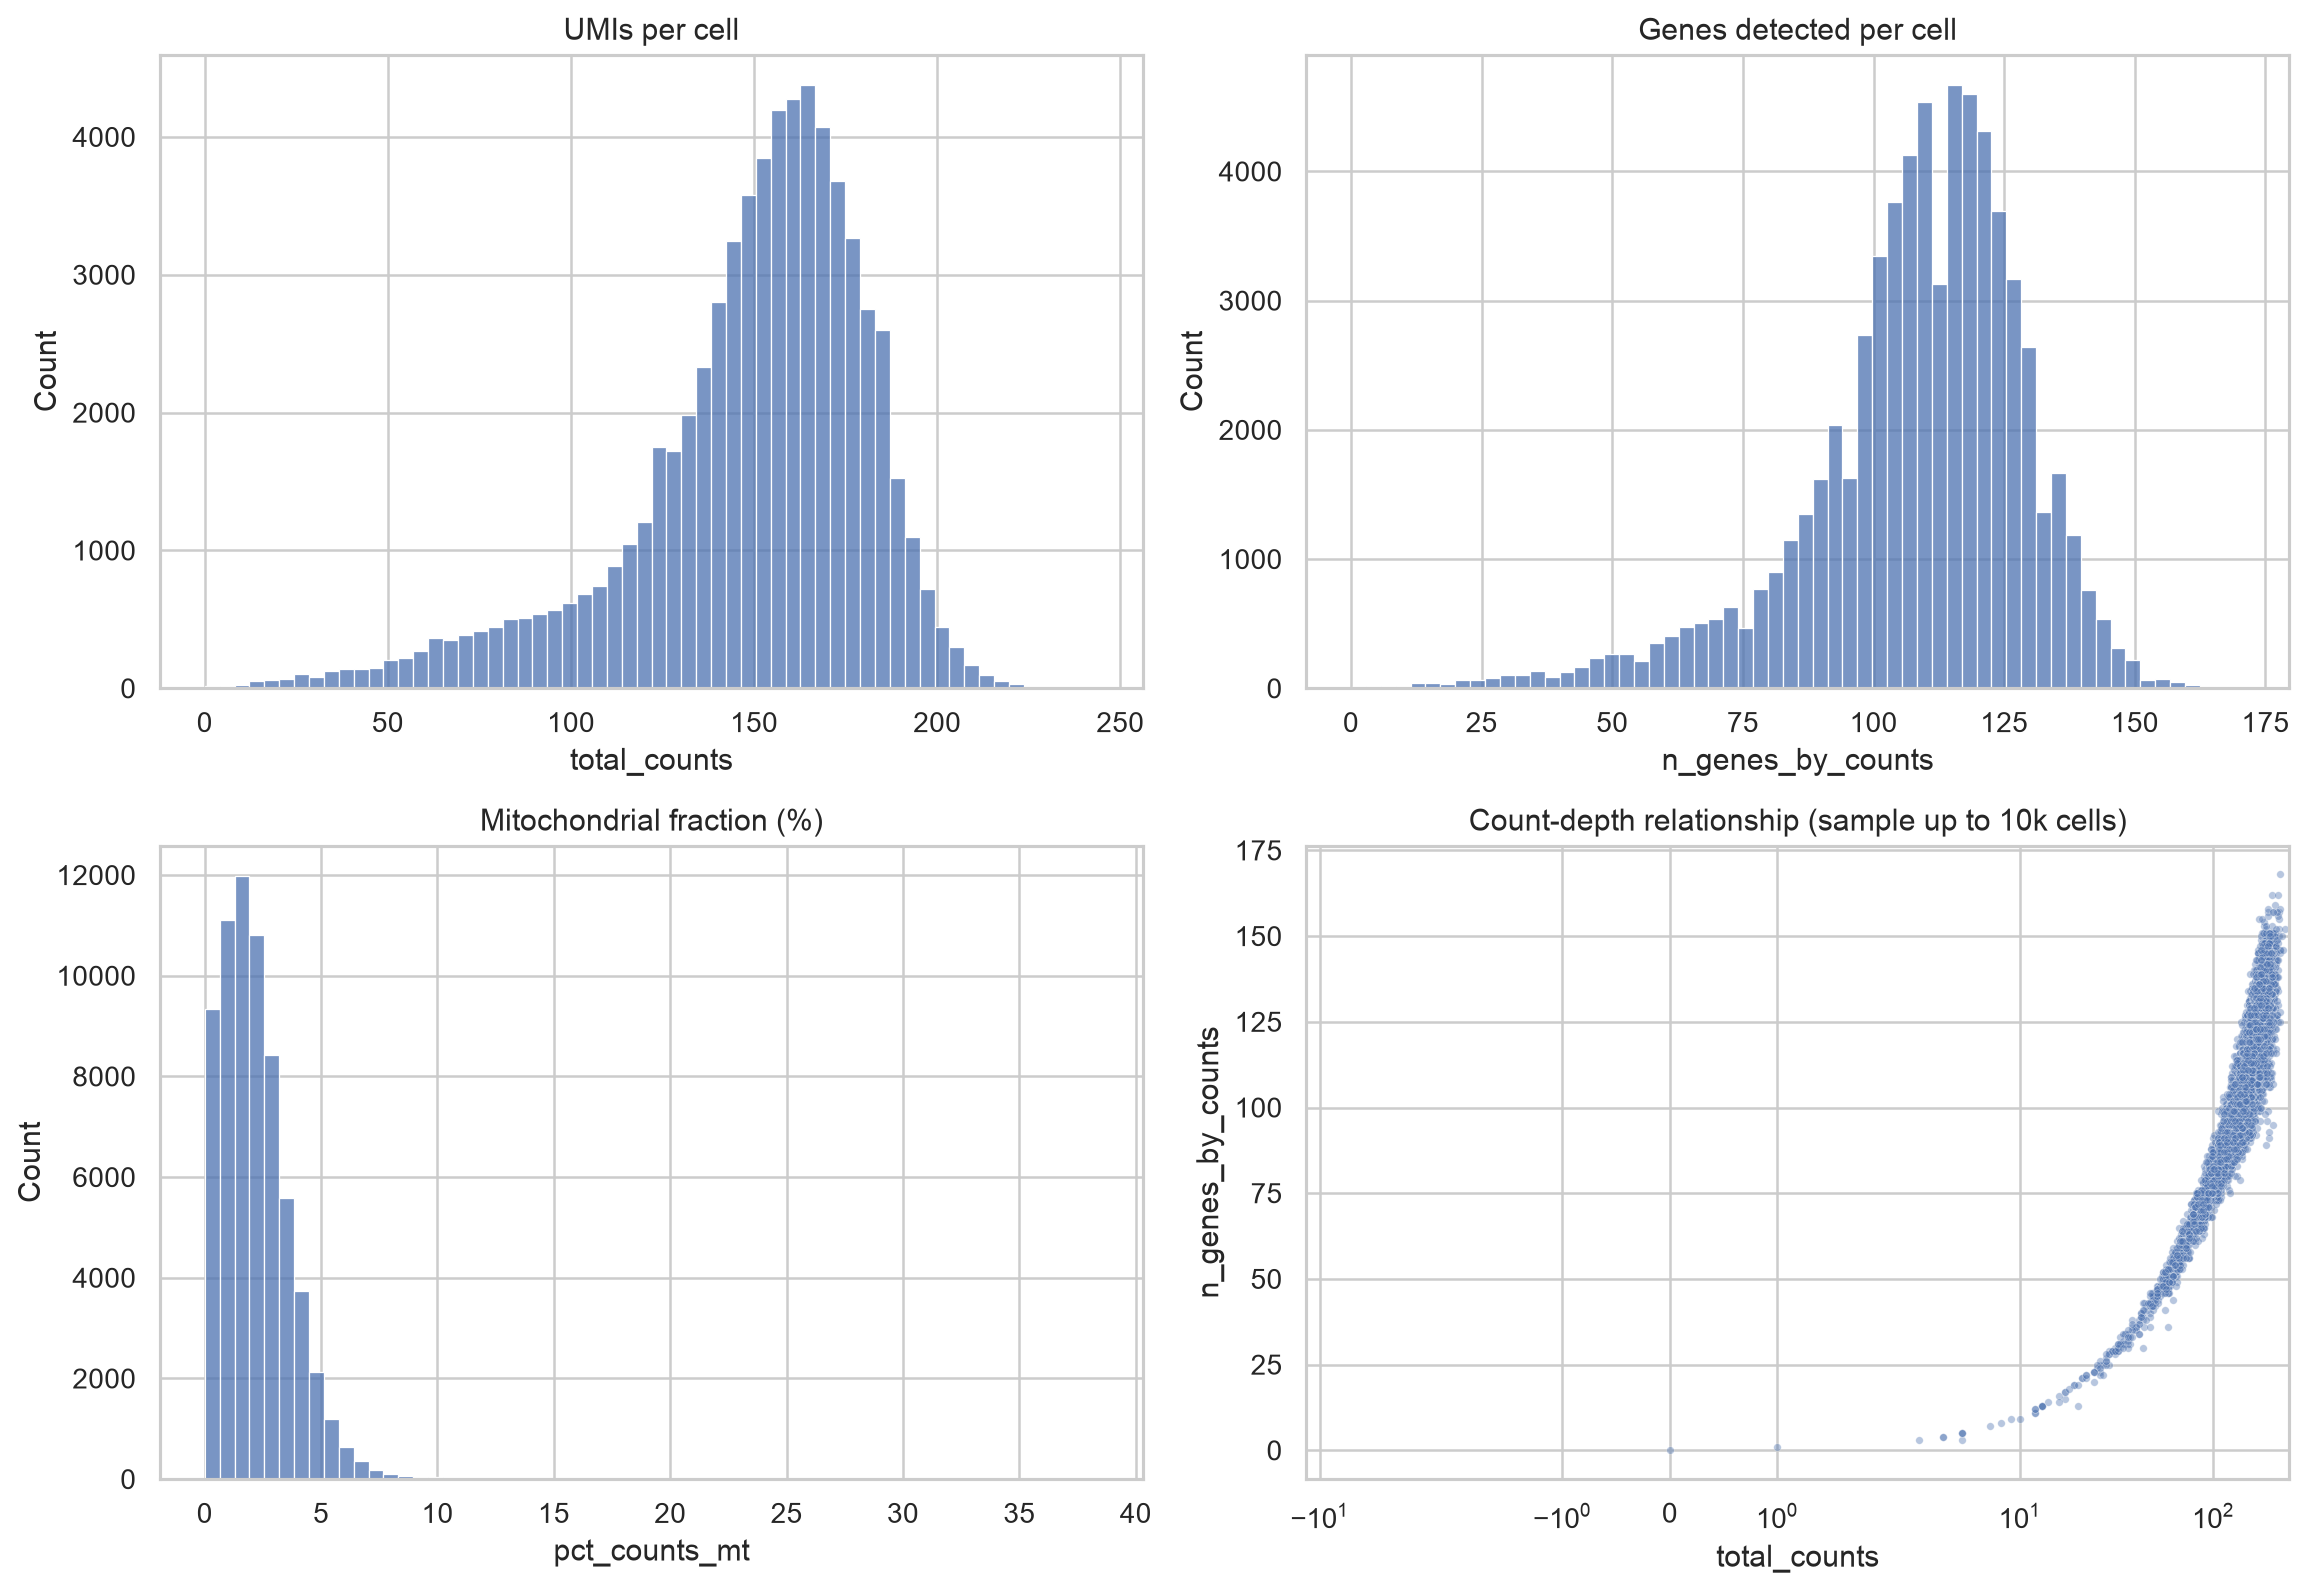

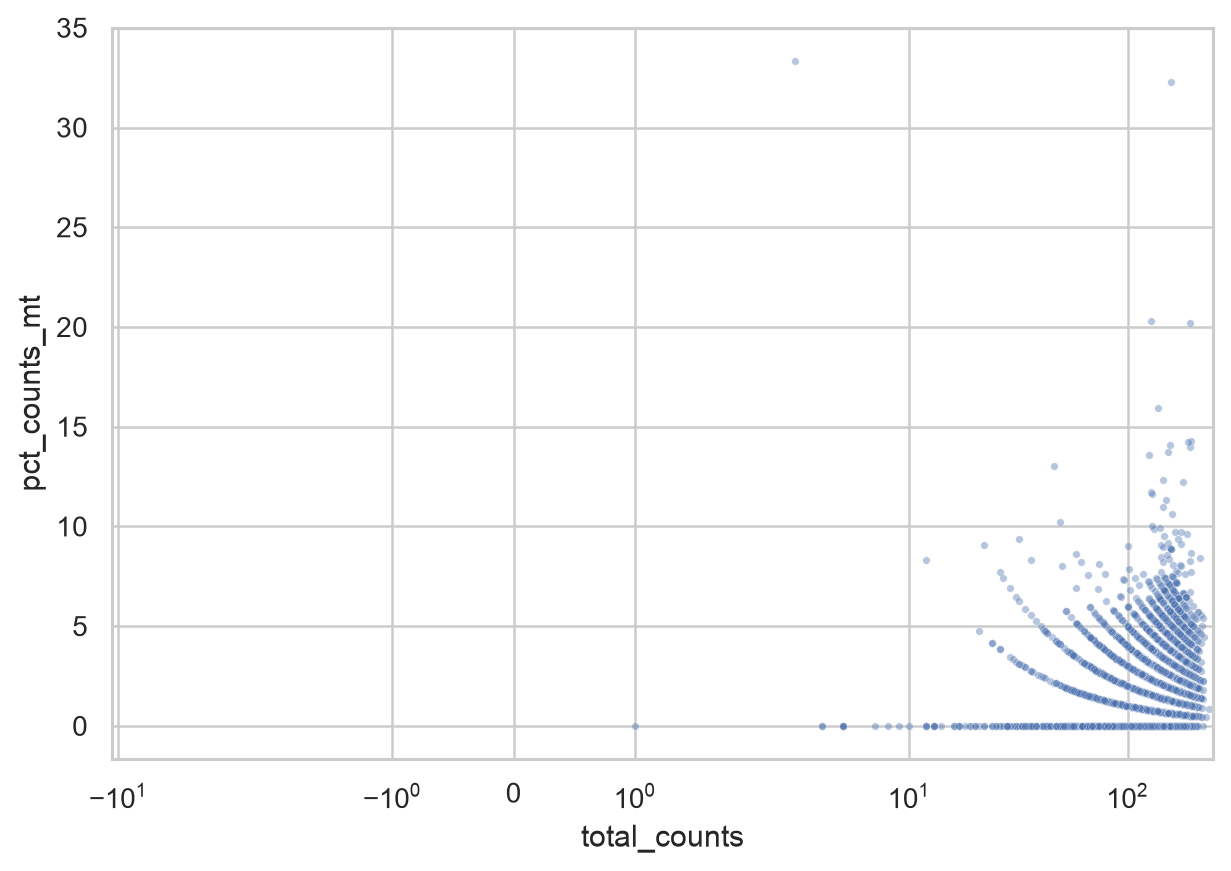

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, title in zip(axes.flat[:3],
                          ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
                          ["UMIs per cell", "Genes detected per cell", "Mitochondrial fraction (%)"]):
    if col in qc.obs:
        sns.histplot(qc.obs[col], bins=60, ax=ax)
        ax.set_title(title)
    else:
        ax.set_visible(False)
sns.scatterplot(data=qc.obs.sample(min(10_000, qc.n_obs), random_state=SEED),
                x="total_counts", y="n_genes_by_counts", s=9, alpha=.4, ax=axes.flat[3])
axes.flat[3].set_xscale("symlog")
axes.flat[3].set_title("Count-depth relationship (sample up to 10k cells)")
plt.tight_layout(); plt.show()
if "pct_counts_mt" in qc.obs:
    fig, ax = plt.subplots(figsize=(7, 5))
    sample = qc.obs.sample(min(10_000, qc.n_obs), random_state=SEED)
    sns.scatterplot(data=sample, x="total_counts", y="pct_counts_mt", s=9, alpha=.4, ax=ax)
    ax.set_xscale("symlog")
    plt.tight_layout(); plt.show()


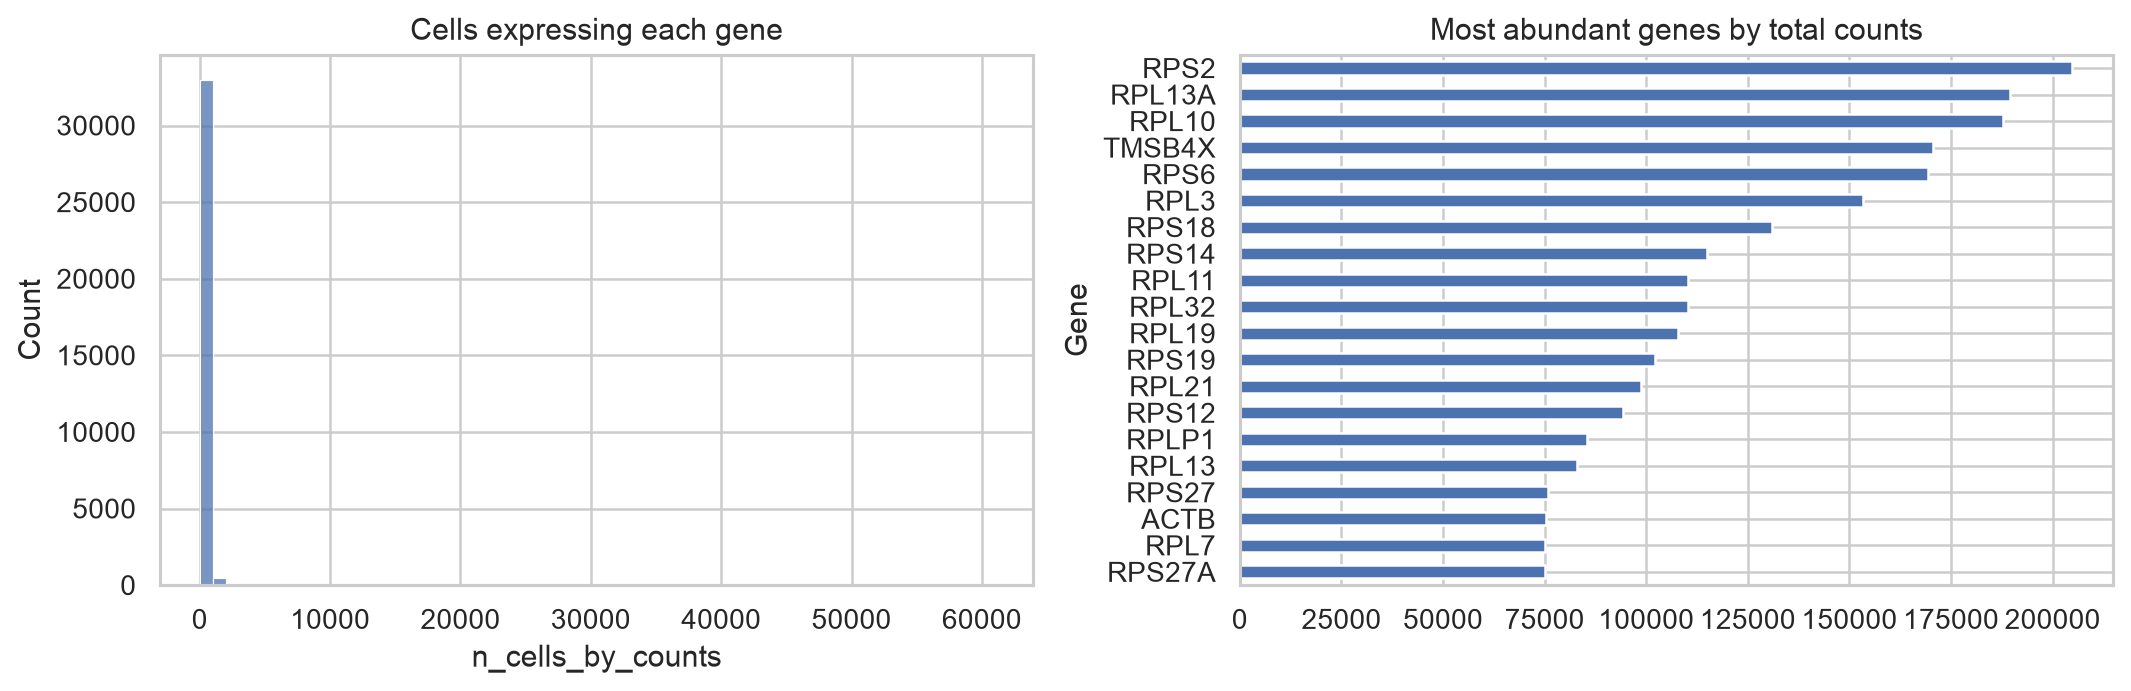

In [62]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(qc.var["n_cells_by_counts"], bins=60, ax=ax[0])
ax[0].set_title("Cells expressing each gene")
top_genes = qc.var["total_counts"].nlargest(min(20, qc.n_vars)).sort_values()
top_genes.plot.barh(ax=ax[1], title="Most abundant genes by total counts")
plt.tight_layout(); plt.show()


### 3. Review and apply QC thresholds
#### Defaults are moderate starting values for single-cell counts; inspect the distributions and adjust them for this file. The table reports how many cells each rule would remove, including overlapping exclusions. Gene filtering follows cell filtering. No cell is dropped on mitochondrial percentage when mitochondrial genes were not identifiable.

In [63]:
MIN_GENES = 150
MIN_COUNTS = 1
MAX_PCT_MT = 20.0
MIN_CELLS_PER_GENE = 3

rules = pd.DataFrame(index=qc.obs_names)
rules["few_genes"] = qc.obs.n_genes_by_counts < MIN_GENES
rules["low_counts"] = qc.obs.total_counts < MIN_COUNTS
if "pct_counts_mt" in qc.obs:
    rules["high_mt"] = qc.obs.pct_counts_mt > MAX_PCT_MT
display(pd.DataFrame({"excluded_by_rule": rules.sum(), "percent_of_cells": 100 * rules.mean()}).round(2))
cell_keep = ~rules.any(axis=1)
print(f"Cell retention: {cell_keep.sum():,}/{qc.n_obs:,} ({cell_keep.mean():.1%})")
if cell_keep.sum() < 3:
    raise ValueError("QC thresholds retain fewer than three cells. Review the plots and adjust them.")
work = qc[cell_keep.to_numpy(), :].copy()
sc.pp.filter_genes(work, min_cells=MIN_CELLS_PER_GENE)
print("After cell and gene QC:", work.shape)
if work.n_vars < 3:
    raise ValueError("Too few genes remain. Adjust MIN_CELLS_PER_GENE.")
qc_decisions = pd.DataFrame({"setting": [MIN_GENES, MIN_COUNTS, MAX_PCT_MT if "pct_counts_mt" in qc.obs else "not applied", MIN_CELLS_PER_GENE],
                             "parameter": ["min_genes", "min_counts", "max_pct_mt", "min_cells_per_gene"]})
display(qc_decisions)


,excluded_by_rule,percent_of_cells
few_genes,65522,99.46
low_counts,1,0.00
high_mt,15,0.02


Cell retention: 355/65,877 (0.5%)
filtered out 30925 genes that are detected in less than 3 cells
After cell and gene QC: (355, 3014)


,setting,parameter
0,150.0,min_genes
1,1.0,min_counts
2,20.0,max_pct_mt
3,3.0,min_cells_per_gene


#### 4. Normalize and find variable genes
Save the validated filtered counts in a layer, then normalize each cell to 10,000 counts and log-transform. The resulting work.X contains log-normalized values. Highly variable genes (HVGs) are selected from this matrix. Gene selection is used for PCA, while all filtered genes remain available for inspection.

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
HVGs: 2000


,means,dispersions,dispersions_norm
Gene,,,
TNFRSF18,0.652652,3.985664,-0.456375
SDF4,1.262406,3.989067,-0.302347
AURKAIP1,1.390916,4.109395,0.201349
MRPL20,0.872484,3.986458,-0.460200
CDK11B,0.382924,4.008599,-0.120503
CDK11A,0.672274,4.339521,1.559099
GNB1,0.401654,4.063423,0.330878
ENO1,1.940374,4.132463,0.187744
CLSTN1,0.563614,3.977055,-0.380207


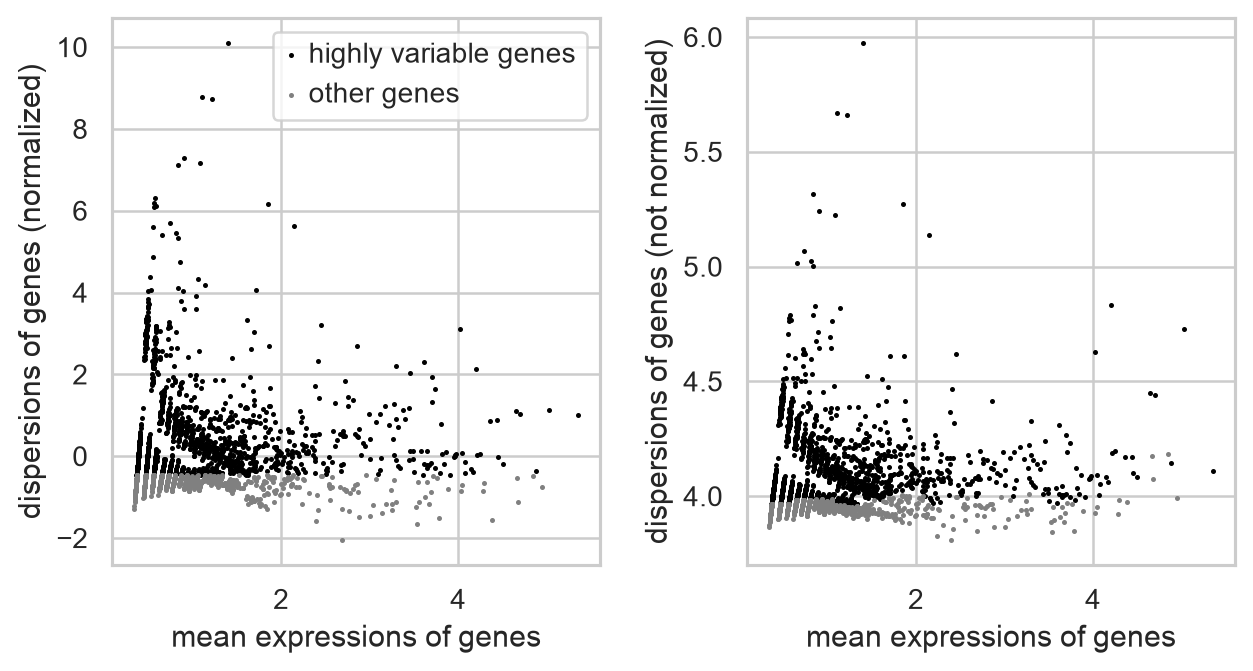

In [64]:
work.layers["counts"] = work.X.copy()
sc.pp.normalize_total(work, target_sum=1e4)
sc.pp.log1p(work)
work.layers["log_normalized"] = work.X.copy()
n_hvg = min(2000, work.n_vars - 1)
sc.pp.highly_variable_genes(work, n_top_genes=n_hvg, flavor="seurat", inplace=True)
print("HVGs:", int(work.var.highly_variable.sum()))
display(work.var.loc[work.var.highly_variable, ["means", "dispersions", "dispersions_norm"]].head(10))
sc.pl.highly_variable_genes(work)


#### 5. PCA, neighborhood graph, UMAP and exploratory clusters
The neighborhood graph and clusters are derived from the same file. Leiden groups are exploratory clusters, not cell type labels. PCA uses HVGs only, with no covariate regression or whole-matrix densification.

computing PCA
    with n_comps=50
    finished (0:00:00)


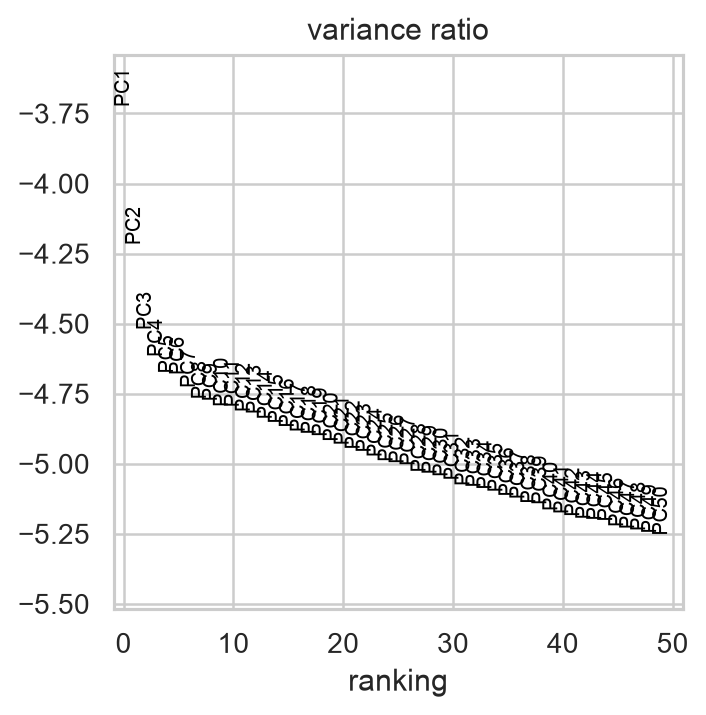

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:08)
computing UMAP
    finished (0:00:02)
running Leiden clustering
    finished (0:00:00)


,cells
leiden_0_6,
0,227
1,99
2,29


PCA components: 50 neighbors: 15


In [65]:
n_pcs = min(50, work.n_obs - 1, int(work.var.highly_variable.sum()) - 1)
if n_pcs < 2:
    raise ValueError("Too few cells or HVGs for PCA.")
sc.pp.pca(work, n_comps=n_pcs, use_highly_variable=True, svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(work, log=True, n_pcs=n_pcs)
neighbors_k = min(15, work.n_obs - 1)
sc.pp.neighbors(work, n_neighbors=neighbors_k, n_pcs=min(30, n_pcs), random_state=SEED)
sc.tl.umap(work, random_state=SEED)
sc.tl.leiden(work, resolution=0.6, key_added="leiden_0_6", flavor="igraph", n_iterations=2)
display(work.obs["leiden_0_6"].value_counts().sort_index().to_frame("cells"))
print("PCA components:", n_pcs, "neighbors:", neighbors_k)


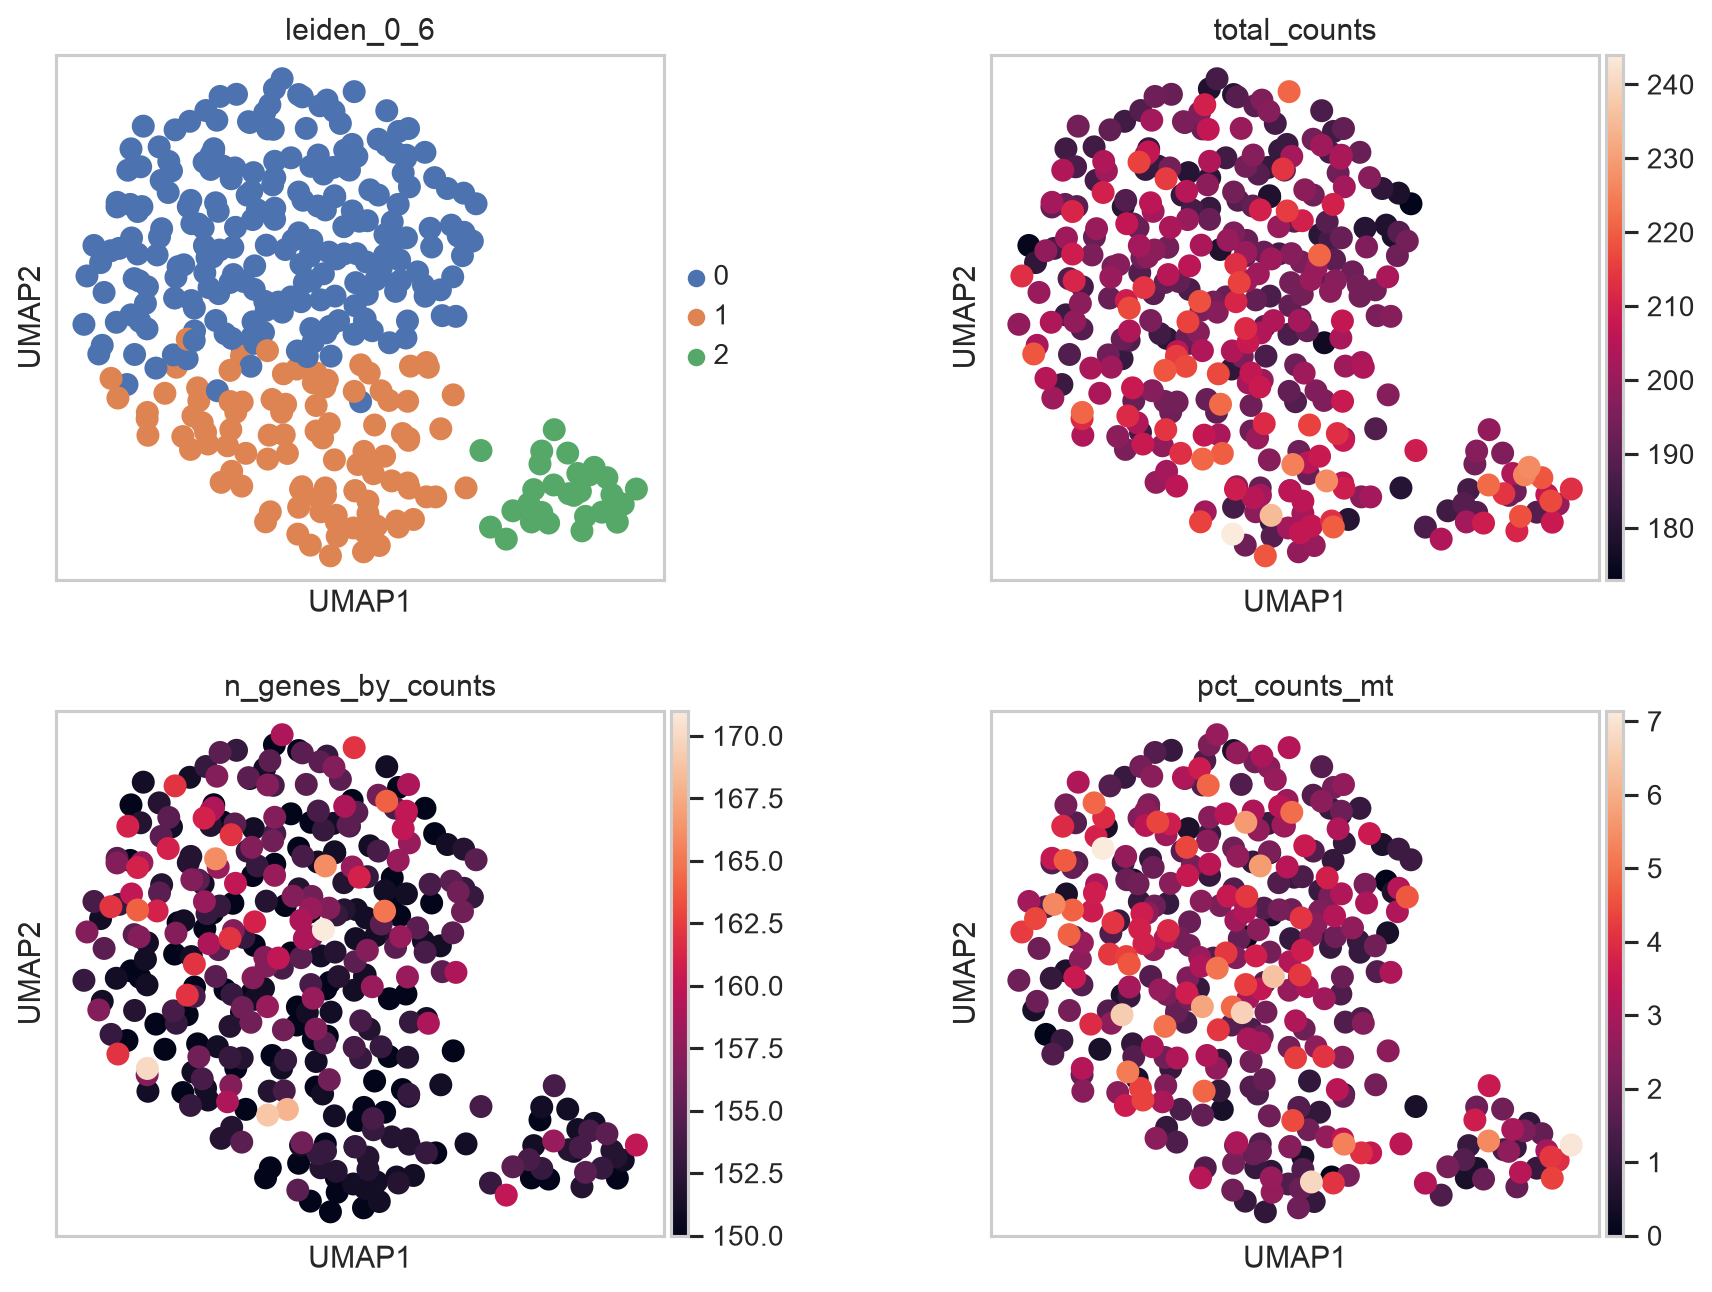

In [66]:
plot_keys = ["leiden_0_6", "total_counts", "n_genes_by_counts"]
if "pct_counts_mt" in work.obs:
    plot_keys.append("pct_counts_mt")
sc.pl.umap(work, color=plot_keys, ncols=2, wspace=.4, show=True)


#### Existing metadata against the embedding
Plot categorical columns with at most 25 levels, if any exist. These columns come from the file; the notebook does not import labels. A clear separation may reflect biology or technical effects and needs interpretation in context.

Eligible existing categorical columns: ['celltype']


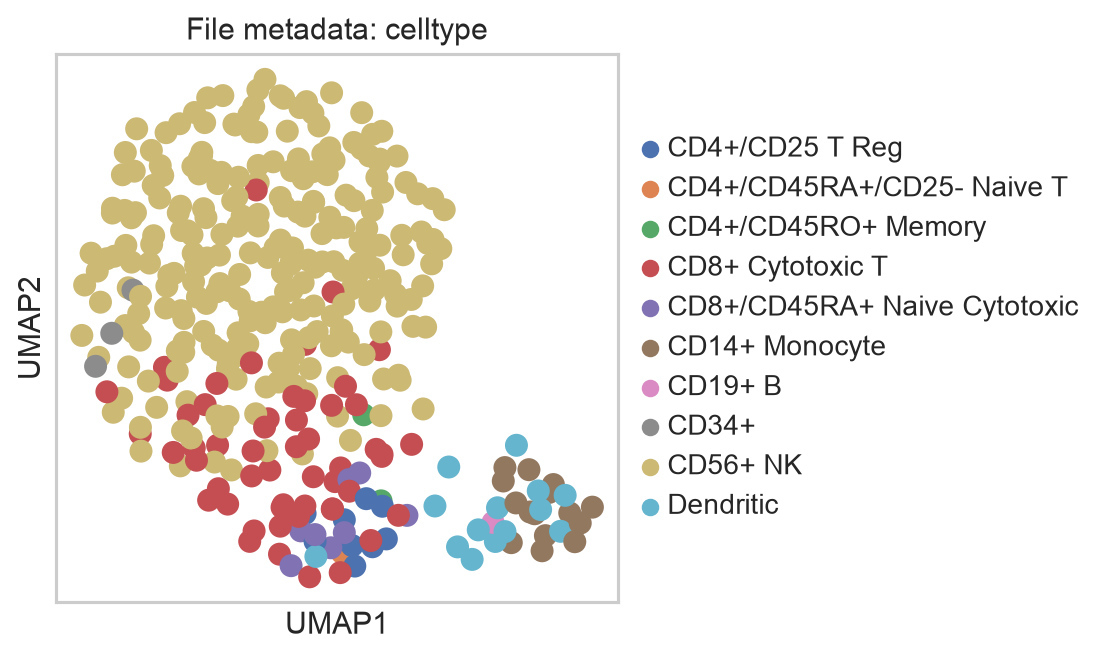

In [67]:
candidate_columns = [c for c in adata.obs.columns
                     if 2 <= adata.obs[c].nunique(dropna=True) <= 25
                     and (pd.api.types.is_categorical_dtype(adata.obs[c]) or
                          pd.api.types.is_object_dtype(adata.obs[c]) or
                          pd.api.types.is_string_dtype(adata.obs[c]))]
print("Eligible existing categorical columns:", candidate_columns)
for column in candidate_columns[:8]:
    sc.pl.umap(work, color=column, title=f"File metadata: {column}", show=True)
if len(candidate_columns) > 8:
    print("Showing first eight columns; inspect candidate_columns for others.")
